In [1]:
%load_ext autoreload
%autoreload 2
import os
import rasterio
import numpy as np
from glob import glob
from tqdm import tqdm
from rasterio.windows import Window
from matplotlib import pyplot as plt

import torch
from torch.utils.data import Dataset, DataLoader
from benchmark import TifSegmentationDataset, benchmark_model
from pathlib import Path

from benchmark import load_terratorch_model, load_geoai_smp_model, predict_terratorch, predict_smp

In [2]:
def show_first3_firstfile(cat, win_w=1024, win_h=1024, lo=2, hi=98):
    img_grep = "images/*.tif"
    # pick first file
    paths = sorted(glob(os.path.join("/workspace_bk/piyush/data/sentinal_datastore", cat, "train", img_grep)))
    if not paths:
        print(f"[{cat}] No files found")
        return
    tif_path = paths[-1]

    with rasterio.open(tif_path) as src:
        bands = min(3, src.count)
        if bands < 3:
            print(f"[{cat}] {os.path.basename(tif_path)} has only {src.count} band(s); skipping")
            return
        
        # central crop window to avoid plotting huge rasters
        w = min(win_w, src.width)
        h = min(win_h, src.height)
        col_off = max(0, (src.width - w) // 2)
        row_off = max(0, (src.height - h) // 2)
        window = Window(col_off=col_off, row_off=row_off, width=w, height=h)

        arr = src.read([1, 2, 3], window=window).astype(np.float32)  # (3, H, W)
        if bands > 6: 
            arr = src.read([2, 3, 4], window=window).astype(np.float32)  # (3, H, W)
    img = arr.transpose(1, 2, 0)  # (H, W, 3)

    # robust per-channel stretch for display
    p_lo = np.percentile(img, lo, axis=(0, 1))
    p_hi = np.percentile(img, hi, axis=(0, 1))
    img = np.clip((img - p_lo) / (p_hi - p_lo + 1e-6), 0, 1)

    plt.figure(figsize=(7, 7))
    plt.imshow(img)
    plt.title(f"{cat} | {os.path.basename(tif_path)} | bands 1-3")
    plt.axis("off")
    plt.show()

def compute_mean_std(image_dir, img_grep, scale=10000):
    paths = glob(os.path.join(image_dir, img_grep))
    n_pixels = 0
    channel_sum = None
    channel_sum_sq = None

    for p in tqdm(paths, desc="Computing mean/std"):
        with rasterio.open(p) as src:
            arr = src.read().astype(np.float64)  # (bands, H, W)
            arr /= scale                         # scale raw DN to ~[0,1]

        b, h, w = arr.shape
        if channel_sum is None:
            channel_sum = np.zeros(b, dtype=np.float64)
            channel_sum_sq = np.zeros(b, dtype=np.float64)

        n_pixels += h * w
        flat = arr.reshape(b, -1)
        channel_sum += flat.sum(axis=1)
        channel_sum_sq += (flat ** 2).sum(axis=1)

    mean = channel_sum / n_pixels
    std  = np.sqrt(channel_sum_sq / n_pixels - mean**2)
    return mean.tolist(), std.tolist()

def compute_class_ratio(mask_dir, mask_grep="masks/*.tif", num_classes=None, ignore_index=None, value_map=None):
    """
    Compute per-class pixel ratios over a set of masks.
    """
    paths = glob(os.path.join(mask_dir, mask_grep))
    if not paths:
        print(f"No mask files found in {mask_dir} with {mask_grep}")
        return {}

    total = None
    for p in tqdm(paths, desc="Computing class ratios"):
        with rasterio.open(p) as src:
            arr = src.read(1).astype(np.int64)

        if value_map:
            mapped = np.full(arr.shape, -1, dtype=np.int64)
            for raw_val, cls_id in value_map.items():
                mapped[arr == raw_val] = cls_id
            arr = mapped
            if ignore_index is None:
                ignore_index = -1

        if ignore_index is not None:
            arr = arr[arr != ignore_index]
        if arr.size == 0:
            continue

        if num_classes is None:
            counts = np.bincount(arr.ravel())
        else:
            counts = np.bincount(arr.ravel(), minlength=num_classes)

        if total is None:
            total = counts.astype(np.int64)
        else:
            if counts.size > total.size:
                total = np.pad(total, (0, counts.size - total.size), constant_values=0)
            elif counts.size < total.size:
                counts = np.pad(counts, (0, total.size - counts.size), constant_values=0)
            total += counts

    if total is None or total.sum() == 0:
        return {"counts": [], "ratios": []}

    ratios = (total / total.sum()).tolist()
    return {"counts": total.tolist(), "ratios": ratios}

def create_dl(test_dir, batch_size=4, num_workers=4, dl_params=None):
    images_dir = os.path.join(test_dir, "images")
    masks_dir = os.path.join(test_dir, "masks")

    if dl_params and dl_params.get("normalization") == "imagenet":
        imagenet_means = [0.485, 0.456, 0.406]
        imagenet_stds = [0.229, 0.224, 0.225]
        geoai_scale = 1 / 255.0  # geoai usually reads uint8 or scales to 0-1
        ds = TifSegmentationDataset( images_dir, masks_dir,
        means=imagenet_means, stds=imagenet_stds, constant_scale=geoai_scale)
    elif dl_params and dl_params.get("normalization") == "standardized":
        # terratorch uses constant_scale + channel-wise norm
        means = dl_params["means"] 
        stds = dl_params["stds"]
        scale = dl_params["scale"] if "scale" in dl_params else 1/10000.0
        ds = TifSegmentationDataset( images_dir, masks_dir, means=means, 
        stds=stds, constant_scale=scale)
    else:
        ds = TifSegmentationDataset(images_dir, masks_dir)
    
    dl = DataLoader(ds, batch_size=batch_size, num_workers=num_workers, shuffle=False, pin_memory=True)
    return dl

def count_trainable_params(module: torch.nn.Module | None) -> int:
    if module is None:
        return 0
    return sum(p.numel() for p in module.parameters() if p.requires_grad)


def get_param_breakdown(model) -> tuple[int, int, int]:
    """Return (encoder_params, decoder_params, total_params) for a model/task."""
    base_model = model.model if hasattr(model, "model") else model
    encoder = getattr(base_model, "encoder", None)
    decoder = getattr(base_model, "decoder", None)
    encoder_params = count_trainable_params(encoder)
    decoder_params = count_trainable_params(decoder)
    total_params = count_trainable_params(base_model)
    return encoder_params, decoder_params, total_params

### RBG

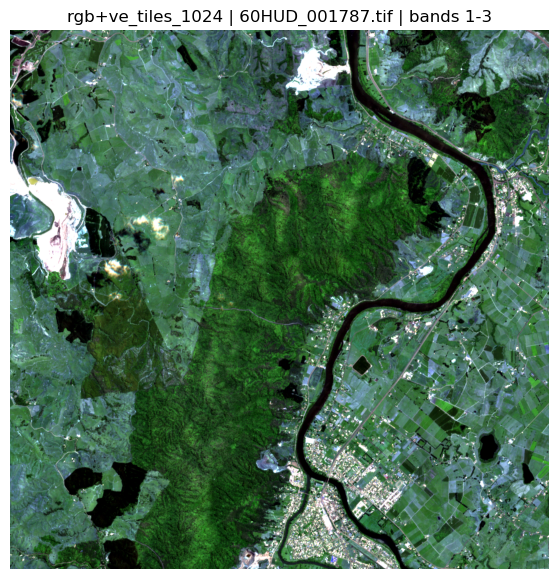

Computed means: [0.10808051888921406, 0.11986660345662084, 0.12866614283181937]
Computed stds : [0.1934757183721109, 0.18732491116331573, 0.19596228303648386]


In [3]:
device = "cuda:0"

num_classes = 2
class_names = ["Not Mine", "Mine"]
test_dir = "/workspace_bk/piyush/data/sentinal_datastore/rgb+ve_tiles_1024/test"

# datacat = ["rgb+ve_tiles_1024", "rgb_nir+ve_tiles_1024", "rgb_irs+ve_tiles_1024"]
# for cat in datacat:
cat = "rgb+ve_tiles_1024"
show_first3_firstfile(cat)
train_data_root = f"/workspace_bk/piyush/data/sentinal_datastore/{cat}/train"

# Dataset root contains masks/ folder
# stats = compute_class_ratio(
#     train_data_root,
#     mask_grep="masks/*.tif",
#     num_classes=2
# )
# print(stats)
# means, stds = compute_mean_std(train_data_root, img_grep = "images/*.tif")
means = [0.10808051888921406, 0.11986660345662084, 0.12866614283181937]
stds = [0.1934757183721109, 0.18732491116331573, 0.19596228303648386]
print("Computed means:", means)
print("Computed stds :", stds)

In [ ]:
from benchmark import get_batch_viz_data


all_results = []

terratorch_save_dir = "/workspace_bk/piyush/runs/terratorch/rgb+ve_1024"
terratorch_ckpts = ["prithvi_frozen_unet_lr1e-4_ce_.25.75_v0/checkpoints/epoch=49-step=44700.ckpt",
                    "prithvi_frozen_unet_lr1e-4_ce_.25.75_v1/best-epoch=48-val_loss=0.0000.ckpt", 
                    "prithvi_frozen_unet_lr1e-4_ce_.25.75_v1/last.ckpt",
                    "prithvi_lr1e-5_unet_lr1e-4_ce_.25.75/checkpoints/epoch=99-step=89400.ckpt",
                    "prithvi_lr1e-5unfreeze10_unet_lr1e-4_ce_.25.75/best-epoch=21-val_loss=0.0000.ckpt",
                    "prithvi_lr1e-5unfreeze10_unet_lr1e-4_ce_.25.75/last.ckpt"]  # List of Terratorch checkpoint paths
model_names = ["frozen_unet_v0_last", "frozen_unet_v1_best", "frozen_unet_v1_last", 
               "unfreeze0_unet_last", "unfreeze10_unet_best", "unfreeze10_unet_last"]  # Corresponding model names for display

output_dir = "/workspace_bk/piyush/runs/geoai_smp/rgb+ve_1024_lr1e-4_epochs200"
geoai_dirs = [d for d in Path(output_dir).glob("*") if d.is_dir()]   

dl_geoai = create_dl(test_dir, batch_size=2, num_workers=4, dl_params={"normalization": "standardized", "means": means, "stds": stds})    
viz_idx = 32
# ---- Benchmark geoai / smp models ----
for model_dir in geoai_dirs:
    model_name = f"geoai::{os.path.basename(model_dir)}"
    print(f"\nLoading geoai model: {model_dir}")
    try:
        model = load_geoai_smp_model(model_dir, num_channel=3, device=device)
        metrics = benchmark_model(
            model_name, predict_smp, model,
            dl_geoai, num_classes, device, class_names
        )
        metrics["checkpoint"] = model_dir
        metrics["encoder_params"], metrics["decoder_params"], metrics["total_params"] = get_param_breakdown(model)
        all_results.append(metrics)
        del model
        torch.cuda.empty_cache()
    except Exception as e:
        print(f"  ✗ Failed: {e}")

dl_terratorch = create_dl(test_dir, batch_size=2, num_workers=4, dl_params={"normalization": "standardized", "means": means, "stds": stds})
for ckpt_path, model_name in zip(terratorch_ckpts, model_names):
        ckpt_path = os.path.join(terratorch_save_dir, ckpt_path)
        model_name = f"terratorch::{model_name}"
        print(f"\nLoading terratorch model: {ckpt_path}")
        try:
            task = load_terratorch_model(ckpt_path, device)
            metrics["encoder_params"], metrics["decoder_params"], metrics["total_params"] = get_param_breakdown(task)
            metrics = benchmark_model(
                model_name, predict_terratorch, task,
                dl_terratorch, num_classes, device, class_names
            )
            metrics["checkpoint"] = ckpt_path
            all_results.append(metrics)
            del task
            torch.cuda.empty_cache()
        except Exception as e:
            print(f"  ✗ Failed: {e}")

In [ ]:
import pandas as pd

df = pd.DataFrame(all_results)
# Reorder columns for readability
col_order = [
    "model", "mIoU", "mF1", "Overall_Accuracy",
    "IoU_Not Mine", "IoU_Mine", "F1_Not Mine", "F1_Mine",
    "Precision_Not Mine", "Precision_Mine", "Recall_Not Mine", "Recall_Mine",
    "mPrecision", "mRecall", "checkpoint", "encoder_params", "decoder_params", "total_params"
]
col_order = [c for c in col_order if c in df.columns]
df = df[col_order]

print("\n" + "=" * 100)
print("BENCHMARK RESULTS")
print("=" * 100)
# Print nicely with pandas
with pd.option_context("display.max_columns", None, "display.width", 200, "display.float_format", "{:.4f}".format):
    print(df.to_string(index=False))
print("=" * 100)
# df.to_csv("benchmark_results.csv", index=False)


BENCHMARK RESULTS
                               model   mIoU    mF1  Overall_Accuracy  IoU_Not Mine  IoU_Mine  F1_Not Mine  F1_Mine  Precision_Not Mine  Precision_Mine  Recall_Not Mine  Recall_Mine  mPrecision  mRecall                                                                                                                         checkpoint  encoder_params  decoder_params   total_params
         geoai::deeplabv3plus_mit_b1 0.5545 0.6295            0.9399        0.9391    0.1699       0.9686   0.2904              0.9458          0.6375           0.9925       0.1881      0.7917   0.5903                                              /workspace_bk/piyush/runs/geoai_smp/rgb+ve_1024_lr1e-4_epochs200/deeplabv3plus_mit_b1   13151424.0000    1152528.0000  14304466.0000
       geoai::deeplabv3plus_resnet50 0.6477 0.7440            0.9510        0.9497    0.3457       0.9742   0.5138              0.9590          0.7331           0.9899       0.3955      0.8461   0.6927                    

### Multipsectral

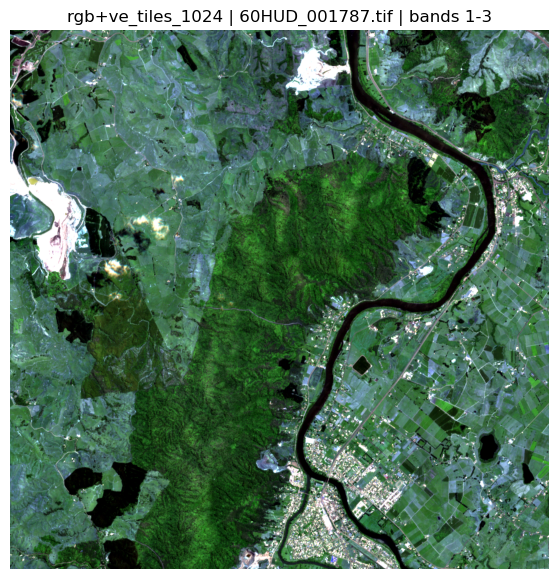

Computing mean/std: 100%|██████████| 1788/1788 [01:20<00:00, 22.11it/s]


Computed means: [0.10808051888921406, 0.11986660345662084, 0.12866614283181937]
Computed stds : [0.1934757183721109, 0.18732491116331573, 0.19596228303648386]
Number of channels for rgb+ve_tiles_1024: 3

Loading geoai model: /workspace_bk/piyush/runs/geoai_smp/rgb+ve_1024_lr1e-4_epochs200/segformer_mit_b1



Loading terratorch model: /workspace_bk/piyush/runs/terratorch/rgb+ve_1024/prithvi_frozen_unet_lr1e-4_ce_.25.75_v0/checkpoints/epoch=49-step=44700.ckpt


/home/piyush/projects/mine-monitor/.pixi/envs/default/lib/python3.14/site-packages/lightly/openapi_generated/swagger_client/api/collaboration_api.py:21: UserWarning: Core Pydantic V1 functionality isn't compatible with Python 3.14 or greater.
  from pydantic.v1 import validate_arguments, ValidationError


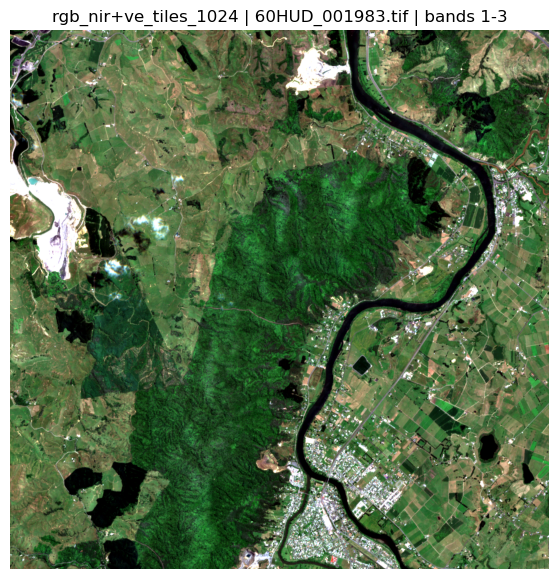

Computing mean/std: 100%|██████████| 1984/1984 [02:04<00:00, 15.96it/s]


Computed means: [0.12454803971715495, 0.11744241986092058, 0.10710630159373255, 0.20427242687267635]
Computed stds : [0.19299162071219028, 0.18615814864941185, 0.19368826952679166, 0.20699387702969146]
Number of channels for rgb_nir+ve_tiles_1024: 4

Loading geoai model: /workspace_bk/piyush/runs/geoai_smp/nc4_bs4_lr1e-4_epochs200/segformer_mit_b1



Loading terratorch model: /workspace_bk/piyush/runs/terratorch/rgb_nir+ve_tiles_1024/prithvi_frozen_unet_lr1e-4_ce_.25.75/best-epoch=11-val_loss=0.0000.ckpt


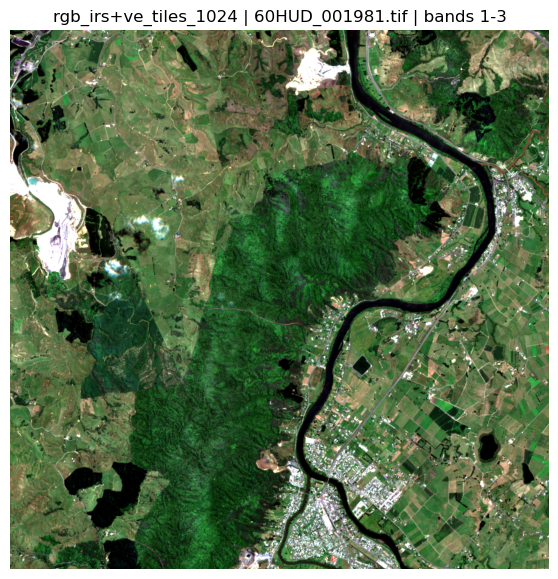

Computing mean/std: 100%|██████████| 1982/1982 [03:04<00:00, 10.72it/s]


Computed means: [0.12461692144122513, 0.11748835596513783, 0.10716054885611168, 0.20447855444772434, 0.1717338935634562, 0.12472681998494414]
Computed stds : [0.19305906501863254, 0.18622984697099554, 0.19376097639648635, 0.20699650249364526, 0.12587038325968888, 0.10388463481088178]
Number of channels for rgb_irs+ve_tiles_1024: 6

Loading geoai model: /workspace_bk/piyush/runs/geoai_smp/nc6_bs4_lr1e-4_epochs200/segformer_mit_b1



Loading terratorch model: /workspace_bk/piyush/runs/terratorch/rgb_irs+ve_tiles_1024/prithvi_frozen_unet_lr1e-4_ce_.25.75/best-epoch=14-val_loss=0.0000.ckpt


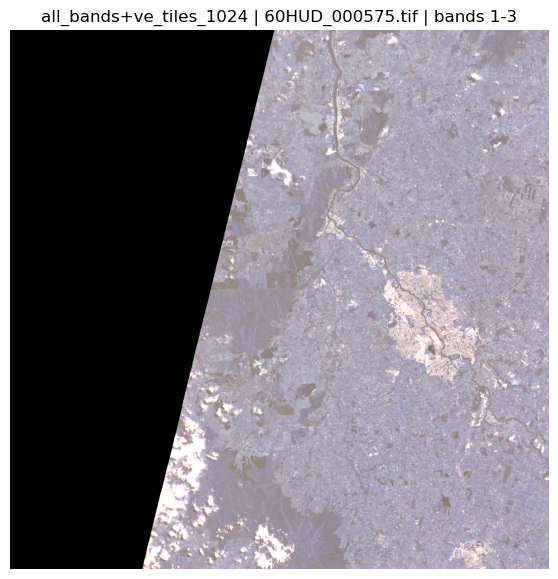

Computing mean/std: 100%|██████████| 576/576 [02:12<00:00,  4.35it/s]


Computed means: [0.1354105677669247, 0.13886522027287224, 0.14777602475997473, 0.15269074693305615, 0.18787118463897046, 0.22884614890035668, 0.24448511302736067, 0.2426125633797715, 0.25504844867736076, 0.26361142865733994, 0.17823492564409962, 0.13203023805982547, 0.010341705764333416, 0.09353366007589625, 0.0004721380891071422]
Computed stds : [0.23281341279733622, 0.23195155785500463, 0.22313104895896524, 0.22755371963158932, 0.23273193263811073, 0.2227988879100007, 0.22045415126953344, 0.2304419537223595, 0.21769123671650045, 0.21883665835868568, 0.12510489602012317, 0.10519078410586914, 0.007126443636489512, 0.10992855663702576, 0.00031464927068133256]
Number of channels for all_bands+ve_tiles_1024: 15

Loading geoai model: /workspace_bk/piyush/runs/geoai_smp/nc15_bs2_lr1e-4_epochs200/segformer_mit_b1



Loading terratorch model: /workspace_bk/piyush/runs/terratorch/
  ✗ Failed: [Errno 21] Is a directory: '/workspace_bk/piyush/runs/terratorch'


In [5]:
device = "cuda:0"

num_classes = 2
class_names = ["Not Mine", "Mine"]
all_results = []
prithvi_base_dir = "/workspace_bk/piyush/runs/terratorch"
geoai_base_dir = "/workspace_bk/piyush/runs/geoai_smp"

datacat = ["rgb+ve_tiles_1024", "rgb_nir+ve_tiles_1024", "rgb_irs+ve_tiles_1024", "all_bands+ve_tiles_1024"]
prithvi_ckpts = ["rgb+ve_1024/prithvi_frozen_unet_lr1e-4_ce_.25.75_v0/checkpoints/epoch=49-step=44700.ckpt",
                 "rgb_nir+ve_tiles_1024/prithvi_frozen_unet_lr1e-4_ce_.25.75/best-epoch=11-val_loss=0.0000.ckpt",
                 "rgb_irs+ve_tiles_1024/prithvi_frozen_unet_lr1e-4_ce_.25.75/best-epoch=14-val_loss=0.0000.ckpt",
                 ""]
segformer_ckpt_dirs = ["rgb+ve_1024_lr1e-4_epochs200/segformer_mit_b1",
                   "nc4_bs4_lr1e-4_epochs200/segformer_mit_b1",
                   "nc6_bs4_lr1e-4_epochs200/segformer_mit_b1",
                   "nc15_bs2_lr1e-4_epochs200/segformer_mit_b1"]
for cat, prithvi_ckpt, segformer_ckpt_dir in zip(datacat, prithvi_ckpts, segformer_ckpt_dirs):
    prithvi_ckpt_path = os.path.join(prithvi_base_dir, prithvi_ckpt)
    segformer_ckpt_path = os.path.join(geoai_base_dir, segformer_ckpt_dir)
    show_first3_firstfile(cat)
    train_data_root = f"/workspace_bk/piyush/data/sentinal_datastore/{cat}/train"
    test_dir = f"/workspace_bk/piyush/data/sentinal_datastore/{cat}/test"
    img_grep = "images/*.tif"
    means, stds = compute_mean_std(train_data_root, img_grep)
    print("Computed means:", means)
    print("Computed stds :", stds)

    num_channel = len(means)
    print(f"Number of channels for {cat}: {num_channel}")
    dataloader = create_dl(test_dir, batch_size=2, num_workers=4, dl_params={"normalization": "standardized", "means": means, "stds": stds})

    print(f"\nLoading geoai model: {segformer_ckpt_path}")
    model_name = f"segformer::{cat}"
    try:
        model = load_geoai_smp_model(segformer_ckpt_path, num_channel, device)
        metrics = benchmark_model(
            model_name, predict_smp, model,
            dataloader, num_classes, device, class_names,
        )
        metrics["checkpoint"] = segformer_ckpt_path
        all_results.append(metrics)
        del model
        torch.cuda.empty_cache()
    except Exception as e:
        print(f"  ✗ Failed: {e}") 

    print(f"\nLoading terratorch model: {prithvi_ckpt_path}")
    model_name = f"prithvi::{cat}"
    try:
        task = load_terratorch_model(prithvi_ckpt_path, device)
        metrics = benchmark_model(
            model_name, predict_terratorch, task,
            dataloader, num_classes, device, class_names,
        )
        metrics["checkpoint"] = prithvi_ckpt_path
        all_results.append(metrics)
        del task
        torch.cuda.empty_cache()
    except Exception as e:
        print(f"  ✗ Failed: {e}")

In [6]:
import pandas as pd

df = pd.DataFrame(all_results)
# Reorder columns for readability
col_order = [
    "model", "mIoU", "mF1", "Overall_Accuracy",
    "IoU_Not Mine", "IoU_Mine", "F1_Not Mine", "F1_Mine",
    "Precision_Not Mine", "Precision_Mine", "Recall_Not Mine", "Recall_Mine",
    "mPrecision", "mRecall", "checkpoint",
]
col_order = [c for c in col_order if c in df.columns]
df = df[col_order]

print("\n" + "=" * 100)
print("BENCHMARK RESULTS")
print("=" * 100)
# Print nicely with pandas
with pd.option_context("display.max_columns", None, "display.width", 200, "display.float_format", "{:.4f}".format):
    print(df.to_string(index=False))
print("=" * 100)


BENCHMARK RESULTS
                             model   mIoU    mF1  Overall_Accuracy  IoU_Not Mine  IoU_Mine  F1_Not Mine  F1_Mine  Precision_Not Mine  Precision_Mine  Recall_Not Mine  Recall_Mine  mPrecision  mRecall                                                                                                                         checkpoint
      segformer::rgb+ve_tiles_1024 0.6894 0.7869            0.9533        0.9516    0.4271       0.9752   0.5986              0.9678          0.6835           0.9827       0.5324      0.8257   0.7576                                                  /workspace_bk/piyush/runs/geoai_smp/rgb+ve_1024_lr1e-4_epochs200/segformer_mit_b1
        prithvi::rgb+ve_tiles_1024 0.6472 0.7503            0.9281        0.9249    0.3695       0.9610   0.5396              0.9744          0.4641           0.9479       0.6445      0.7193   0.7962      /workspace_bk/piyush/runs/terratorch/rgb+ve_1024/prithvi_frozen_unet_lr1e-4_ce_.25.75_v0/checkpoints/epoch=49-step

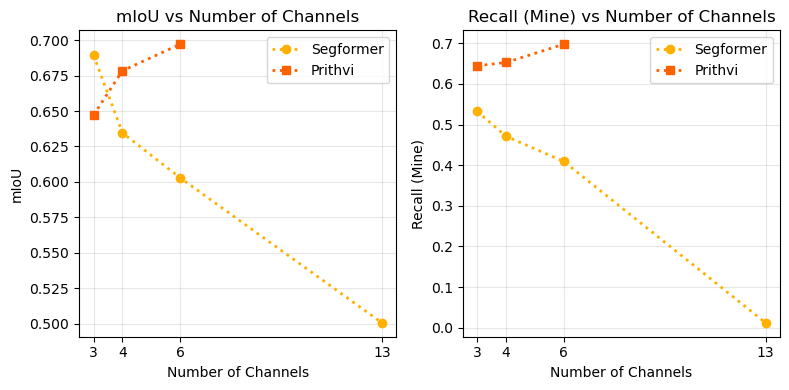

In [ ]:
# Filter results for segformer and prithvi models across different channel counts
segformer_results = [r for r in all_results if 'segformer' in r['model']]
prithvi_results = [r for r in all_results if 'prithvi' in r['model']]

# Extract metrics
segformer_miou = [r['mIoU'] for r in segformer_results]
segformer_recall_mine = [r['Recall_Mine'] for r in segformer_results]
prithvi_miou = [r['mIoU'] for r in prithvi_results]
prithvi_recall_mine = [r['Recall_Mine'] for r in prithvi_results]

# Channel counts: 3 (RGB), 4 (RGB+NIR), 6 (RGB+IRS), 13 (all_bands)
channels = [3, 4, 6, 15]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4))

# mIoU plot
ax1.plot(channels[:len(segformer_miou)], segformer_miou, marker='o', label='Segformer', linewidth=2, linestyle=':', color='#FFB000')
ax1.plot(channels[:len(prithvi_miou)], prithvi_miou, marker='s', label='Prithvi', linewidth=2, linestyle=':', color='#FE6100')
ax1.set_xlabel('Number of Channels')
ax1.set_ylabel('mIoU')
ax1.set_title('mIoU vs Number of Channels')
ax1.legend()
ax1.grid(True, alpha=0.3)
ax1.set_xticks(channels)

# Recall_Mine plot
ax2.plot(channels[:len(segformer_recall_mine)], segformer_recall_mine, marker='o', label='Segformer', linewidth=2, linestyle=':', color='#FFB000')
ax2.plot(channels[:len(prithvi_recall_mine)], prithvi_recall_mine, marker='s', label='Prithvi', linewidth=2, linestyle=':', color='#FE6100')
ax2.set_xlabel('Number of Channels')
ax2.set_ylabel('Recall (Mine)')
ax2.set_title('Recall (Mine) vs Number of Channels')
ax2.legend()
ax2.grid(True, alpha=0.3)
ax2.set_xticks(channels)

plt.tight_layout()
plt.show()